# 03 — Purchase prediction and factor ranking

This notebook fits a transparent NumPy logistic regression. All learned transformations and model settings are fit or selected using training and validation data only. The test split is evaluated once after the model, regularization, and optional F1 threshold are locked.

The primary model excludes `Revenue`, the synthetic `row_id`, and `PageValues`. A separate sensitivity model includes `PageValues`; it is not treated as deployable because its transaction-linked timing is uncertain.


Not converged: 0.01 0.001 iteration_limit


Not converged: 0.01 0.01 iteration_limit


Not converged: 0.01 0.1 iteration_limit


Not converged: 0.05 0.001 iteration_limit


Not converged: 0.05 0.01 iteration_limit


/var/folders/1v/x40mbg4x6cdfmck1r6g8xdnc0000gn/T/ipykernel_61143/1067135594.py:43: RuntimeWarning: divide by zero encountered in matmul
  candidates.append({'learning_rate': learning_rate, 'l2': l2, 'validation_log_loss': classification_metrics(y_validation, validation_probability)['log_loss'], 'iterations': result['iterations'], 'gradient_norm': float(np.linalg.norm((X_train.T @ (predict_proba(X_train, result['beta']) - y_train) / len(y_train))[1:])), 'converged': result['converged'], 'reason': result['reason'], 'result': result})
/var/folders/1v/x40mbg4x6cdfmck1r6g8xdnc0000gn/T/ipykernel_61143/1067135594.py:43: RuntimeWarning: overflow encountered in matmul
  candidates.append({'learning_rate': learning_rate, 'l2': l2, 'validation_log_loss': classification_metrics(y_validation, validation_probability)['log_loss'], 'iterations': result['iterations'], 'gradient_norm': float(np.linalg.norm((X_train.T @ (predict_proba(X_train, result['beta']) - y_train) / len(y_train))[1:])), 'converged'

Not converged: 0.1 0.001 iteration_limit


Not converged: 0.1 0.01 iteration_limit


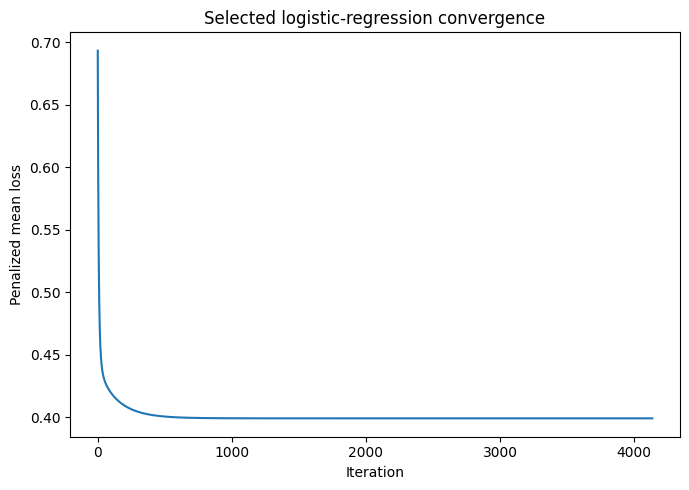

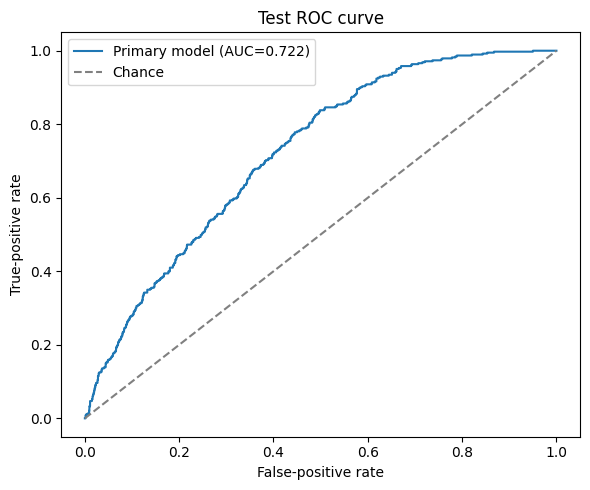

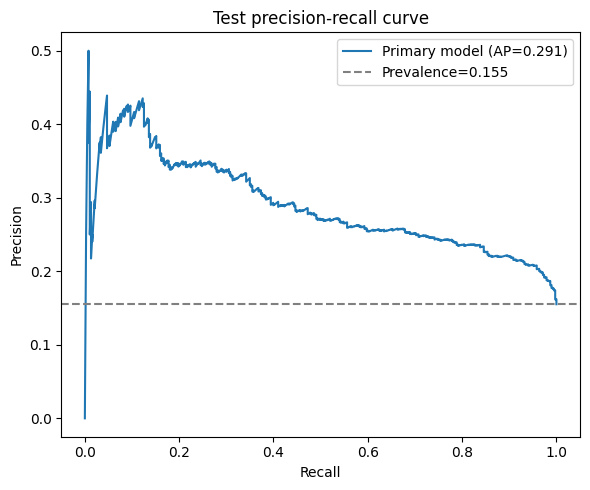

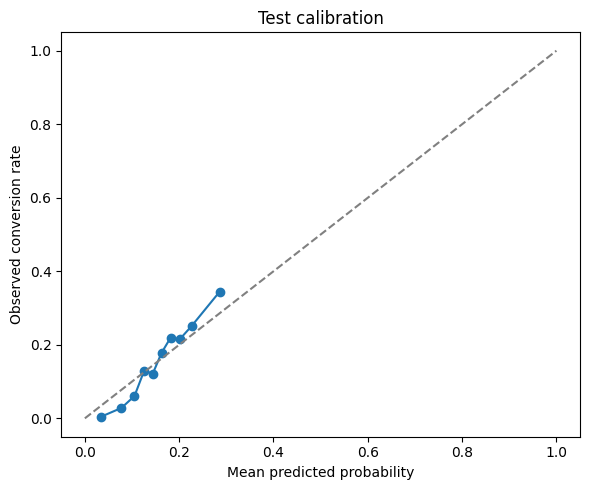

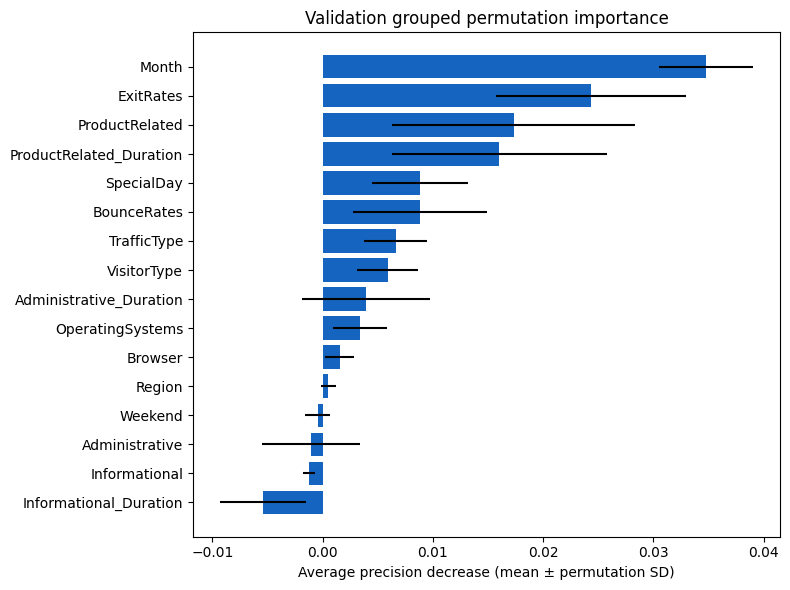

Selected: {'learning_rate': 0.1, 'l2': 0.1} validation log loss: 0.38655908310529125 threshold: 0.17165109081952018
              model      split  log_loss  average_precision       f1  threshold
 always_no_purchase validation  5.338448           0.154564 0.000000   0.500000
training_prevalence validation  0.430545           0.154564 0.000000   0.500000
   primary_logistic validation  0.386559           0.337025 0.000000   0.500000
 always_no_purchase       test  5.359948           0.155186 0.000000   0.500000
training_prevalence       test  0.431602           0.155186 0.000000   0.500000
   primary_logistic       test  0.392837           0.291022 0.000000   0.500000
   primary_logistic validation  0.386559           0.337025 0.395026   0.171651
   primary_logistic       test  0.392837           0.291022 0.371553   0.171651
Top validation factors: Month, ExitRates, ProductRelated, ProductRelated_Duration, SpecialDay


In [1]:
from IPython.display import display
import sys
from pathlib import Path
_base = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(_base))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import ROOT
from src.modeling import (TrainingPreprocessor, fit_logistic, predict_proba,
    classification_metrics, best_f1_threshold, roc_curve, average_precision)

SEED = 42
rng = np.random.default_rng(SEED)
clean = ROOT / 'data/processed/clean_sessions.csv'
splits = ROOT / 'data/processed/split_assignments.csv'
if not clean.exists() or not splits.exists():
    raise FileNotFoundError('Run Notebook 01 first.')
df = pd.read_csv(clean).merge(pd.read_csv(splits), on='row_id')
train = df[df.split == 'train'].copy(); validation = df[df.split == 'validation'].copy(); test = df[df.split == 'test'].copy()
target = 'Revenue'
numeric = ('Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'SpecialDay')
categorical = ('Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend')
primary_features = list(numeric + categorical)
tables = ROOT / 'reports/tables'; figures = ROOT / 'reports/figures'; tables.mkdir(parents=True, exist_ok=True); figures.mkdir(parents=True, exist_ok=True)

# Every transformation is fitted on train only. PageValues is excluded from this model.
preprocessor = TrainingPreprocessor(numeric, categorical).fit(train)
pd.DataFrame({'feature': preprocessor.feature_names, 'primary_model_feature': True}).to_csv(tables / 'preprocessing_metadata.csv', index=False)
X_train = preprocessor.transform(train); X_validation = preprocessor.transform(validation); X_test = preprocessor.transform(test)
y_train = train[target].astype(int).to_numpy(); y_validation = validation[target].astype(int).to_numpy(); y_test = test[target].astype(int).to_numpy()
assert X_train.shape[1] == X_validation.shape[1] == X_test.shape[1]

learning_rates = (.01, .05, .1); l2_values = (.001, .01, .1)
candidates = []
for learning_rate in learning_rates:
    for l2 in l2_values:
        result = fit_logistic(X_train, y_train, learning_rate=learning_rate, l2=l2, max_iter=10000, tolerance=1e-7)
        if not result['converged']:
            print('Not converged:', learning_rate, l2, result['reason'])
            continue
        validation_probability = predict_proba(X_validation, result['beta'])
        candidates.append({'learning_rate': learning_rate, 'l2': l2, 'validation_log_loss': classification_metrics(y_validation, validation_probability)['log_loss'], 'iterations': result['iterations'], 'gradient_norm': float(np.linalg.norm((X_train.T @ (predict_proba(X_train, result['beta']) - y_train) / len(y_train))[1:])), 'converged': result['converged'], 'reason': result['reason'], 'result': result})
if not candidates:
    raise RuntimeError('No logistic-regression candidate converged.')
selection = pd.DataFrame([{k: v for k, v in row.items() if k != 'result'} for row in candidates]).sort_values('validation_log_loss')
selected_row = min(candidates, key=lambda row: row['validation_log_loss'])
selected = selected_row['result']; selected_params = {k: selected_row[k] for k in ('learning_rate', 'l2')}
selection.to_csv(tables / 'validation_model_selection.csv', index=False)
pd.DataFrame([{'parameter': key, 'value': value} for key, value in selected_params.items()]).to_csv(tables / 'selected_model_parameters.csv', index=False)
pd.DataFrame({'iteration': np.arange(1, len(selected['losses']) + 1), 'loss': selected['losses']}).to_csv(tables / 'convergence_log.csv', index=False)

# Validation selects the optional F1 threshold; test is evaluated only after choices are locked.
validation_probability = predict_proba(X_validation, selected['beta'])
threshold_05 = .5; selected_threshold = best_f1_threshold(y_validation, validation_probability)
prevalence = y_train.mean()
baseline_validation = np.full(len(y_validation), prevalence); baseline_test = np.full(len(y_test), prevalence)
metrics_rows = []
for name, split_name, y, probability in [('always_no_purchase', 'validation', y_validation, np.zeros(len(y_validation))), ('training_prevalence', 'validation', y_validation, baseline_validation), ('primary_logistic', 'validation', y_validation, validation_probability), ('always_no_purchase', 'test', y_test, np.zeros(len(y_test))), ('training_prevalence', 'test', y_test, baseline_test), ('primary_logistic', 'test', y_test, predict_proba(X_test, selected['beta']))]:
    metrics_rows.append(dict(model=name, split=split_name, **classification_metrics(y, probability, threshold_05)))
for split_name, y, probability in [('validation', y_validation, validation_probability), ('test', y_test, predict_proba(X_test, selected['beta']))]:
    metrics_rows.append(dict(model='primary_logistic', split=split_name, **classification_metrics(y, probability, selected_threshold)))
metrics = pd.DataFrame(metrics_rows); metrics.to_csv(tables / 'model_metrics.csv', index=False)
cm = classification_metrics(y_test, primary_test_probability, selected_threshold) if 'primary_test_probability' in locals() else classification_metrics(y_test, predict_proba(X_test, selected['beta']), selected_threshold)
pd.DataFrame({'actual': ['negative', 'positive'], 'predicted_negative': [cm['tn'], cm['fn']], 'predicted_positive': [cm['fp'], cm['tp']]}).to_csv(tables / 'primary_test_confusion_matrix.csv', index=False)
pd.DataFrame([{'threshold_name': 'validation_f1_maximizing', 'threshold': selected_threshold, 'validation_f1': classification_metrics(y_validation, validation_probability, selected_threshold)['f1'], 'selection_split': 'validation'}]).to_csv(tables / 'selected_threshold.csv', index=False)

# Coefficients are complementary, not a mixed-scale ranking.
coefficients = pd.DataFrame({'feature': preprocessor.feature_names[1:], 'coefficient': selected['beta'][1:]})
coefficients['odds_ratio'] = np.exp(coefficients['coefficient']); coefficients.to_csv(tables / 'primary_model_coefficients.csv', index=False)

# Grouped permutation importance uses validation AP, preserving one permutation for each dummy block.
validation_ap = average_precision(y_validation, validation_probability)
feature_groups = {feature: ([preprocessor.feature_names.index(feature)] if feature in preprocessor.feature_names else preprocessor.groups[feature]) for feature in primary_features}
importance_rows = []
for feature in primary_features:
    decreases = []
    for _ in range(30):
        permuted = validation.copy()
        order = rng.permutation(len(permuted)); permuted[feature] = permuted[feature].to_numpy()[order]
        score = average_precision(y_validation, predict_proba(preprocessor.transform(permuted), selected['beta']))
        decreases.append(validation_ap - score)
    importance_rows.append({'feature': feature, 'baseline_average_precision': validation_ap, 'mean_ap_decrease': np.mean(decreases), 'sd_ap_decrease': np.std(decreases, ddof=1), 'repetitions': 30, 'split': 'validation'})
importance = pd.DataFrame(importance_rows).sort_values('mean_ap_decrease', ascending=False); importance.to_csv(tables / 'validation_grouped_permutation_importance.csv', index=False)

# PageValues sensitivity: same train/validation selection protocol, separate from primary conclusions.
sensitivity_preprocessor = TrainingPreprocessor(numeric, categorical, include_page_values=True).fit(train)
SX_train = sensitivity_preprocessor.transform(train); SX_validation = sensitivity_preprocessor.transform(validation); SX_test = sensitivity_preprocessor.transform(test)
sensitivity_candidates = []
for learning_rate in learning_rates:
    for l2 in l2_values:
        result = fit_logistic(SX_train, y_train, learning_rate=learning_rate, l2=l2, max_iter=10000, tolerance=1e-7)
        if result['converged']:
            probability = predict_proba(SX_validation, result['beta'])
            sensitivity_candidates.append((classification_metrics(y_validation, probability)['log_loss'], learning_rate, l2, result))
if not sensitivity_candidates:
    raise RuntimeError('No PageValues sensitivity candidate converged.')
sensitivity_loss, sensitivity_lr, sensitivity_l2, sensitivity_result = min(sensitivity_candidates, key=lambda row: row[0])
sensitivity_test_probability = predict_proba(SX_test, sensitivity_result['beta'])
sensitivity_validation_probability = predict_proba(SX_validation, sensitivity_result['beta'])
sensitivity_threshold = best_f1_threshold(y_validation, sensitivity_validation_probability)
sensitivity_metrics = pd.DataFrame([dict(model='PageValues_sensitivity', split='validation', **classification_metrics(y_validation, sensitivity_validation_probability, sensitivity_threshold)), dict(model='PageValues_sensitivity', split='test', **classification_metrics(y_test, sensitivity_test_probability, sensitivity_threshold)), {'model':'PageValues_sensitivity', 'split':'selection', 'validation_log_loss':sensitivity_loss, 'learning_rate':sensitivity_lr, 'l2':sensitivity_l2, 'iterations':sensitivity_result['iterations'], 'converged':sensitivity_result['converged'], 'selected_threshold':sensitivity_threshold}])
sensitivity_metrics.to_csv(tables / 'pagevalues_sensitivity_metrics.csv', index=False)

# Required model figures.
primary_test_probability = predict_proba(X_test, selected['beta'])
fig, ax = plt.subplots(figsize=(7, 5)); ax.plot(selected['losses']); ax.set(xlabel='Iteration', ylabel='Penalized mean loss', title='Selected logistic-regression convergence'); fig.tight_layout(); fig.savefig(figures / '08_logistic_loss_curve.png', dpi=220); display(fig); plt.close(fig)
fpr, tpr, _ = roc_curve(y_test, primary_test_probability); fig, ax = plt.subplots(figsize=(6, 5)); ax.plot(fpr, tpr, label=f'Primary model (AUC={classification_metrics(y_test, primary_test_probability)["roc_auc"]:.3f})'); ax.plot([0,1],[0,1],'--',color='grey',label='Chance'); ax.set(xlabel='False-positive rate', ylabel='True-positive rate', title='Test ROC curve'); ax.legend(); fig.tight_layout(); fig.savefig(figures / '09_test_roc_curve.png', dpi=220); display(fig); plt.close(fig)
order = np.argsort(-primary_test_probability); ys = y_test[order]; precision = np.cumsum(ys) / np.arange(1, len(ys)+1); recall = np.cumsum(ys) / max(ys.sum(), 1); fig, ax = plt.subplots(figsize=(6,5)); ax.plot(recall, precision, label=f'Primary model (AP={average_precision(y_test, primary_test_probability):.3f})'); ax.axhline(y_test.mean(), linestyle='--', color='grey', label=f'Prevalence={y_test.mean():.3f}'); ax.set(xlabel='Recall', ylabel='Precision', title='Test precision-recall curve'); ax.legend(); fig.tight_layout(); fig.savefig(figures / '10_test_precision_recall_curve.png', dpi=220); display(fig); plt.close(fig)
quantiles = pd.qcut(primary_test_probability, q=10, duplicates='drop'); calibration = pd.DataFrame({'y': y_test, 'p': primary_test_probability, 'bin': quantiles}).groupby('bin', observed=True).agg(mean_predicted=('p','mean'), observed_rate=('y','mean'), sessions=('y','size')).reset_index(); calibration.to_csv(tables / 'test_calibration_bins.csv', index=False); fig, ax = plt.subplots(figsize=(6,5)); ax.plot(calibration.mean_predicted, calibration.observed_rate, 'o-'); ax.plot([0,1],[0,1],'--',color='grey'); ax.set(xlabel='Mean predicted probability', ylabel='Observed conversion rate', title='Test calibration'); fig.tight_layout(); fig.savefig(figures / '11_test_calibration.png', dpi=220); display(fig); plt.close(fig)
rank_plot = importance.sort_values('mean_ap_decrease'); fig, ax = plt.subplots(figsize=(8,6)); ax.barh(rank_plot.feature, rank_plot.mean_ap_decrease, xerr=rank_plot.sd_ap_decrease, color='#1565c0'); ax.set(xlabel='Average precision decrease (mean ± permutation SD)', title='Validation grouped permutation importance'); fig.tight_layout(); fig.savefig(figures / '12_validation_grouped_permutation_importance.png', dpi=220); display(fig); plt.close(fig)
print('Selected:', selected_params, 'validation log loss:', selected_row['validation_log_loss'], 'threshold:', selected_threshold)
print(metrics[['model','split','log_loss','average_precision','f1','threshold']].to_string(index=False))
print('Top validation factors:', ', '.join(importance.head(5).feature))


## Interpretation boundaries

Coefficients are complementary descriptions of this fitted model, not p-values or causal effects. Grouped permutation importance is computed on validation data and retains negative estimates; its standard deviation is permutation variability, not a confidence interval. A high-ranked factor is useful for this model and sample, not inherently the cause of purchasing. Correlated counts, durations, and rates can dilute individual importance.


## Findings

The printed tables and saved CSVs provide the actual validation and test results. Compare the primary model with both baselines using average precision and log loss, not accuracy alone. The selected threshold maximizes validation F1 and is then frozen for test reporting; it is a technical trade-off, not an economically optimal campaign threshold because costs and purchase values are unavailable.

The PageValues sensitivity result must be read separately: an improvement would show that this transaction-linked feature is predictive in the retrospective sample, not that it is available early enough for live targeting or that it causes conversion.


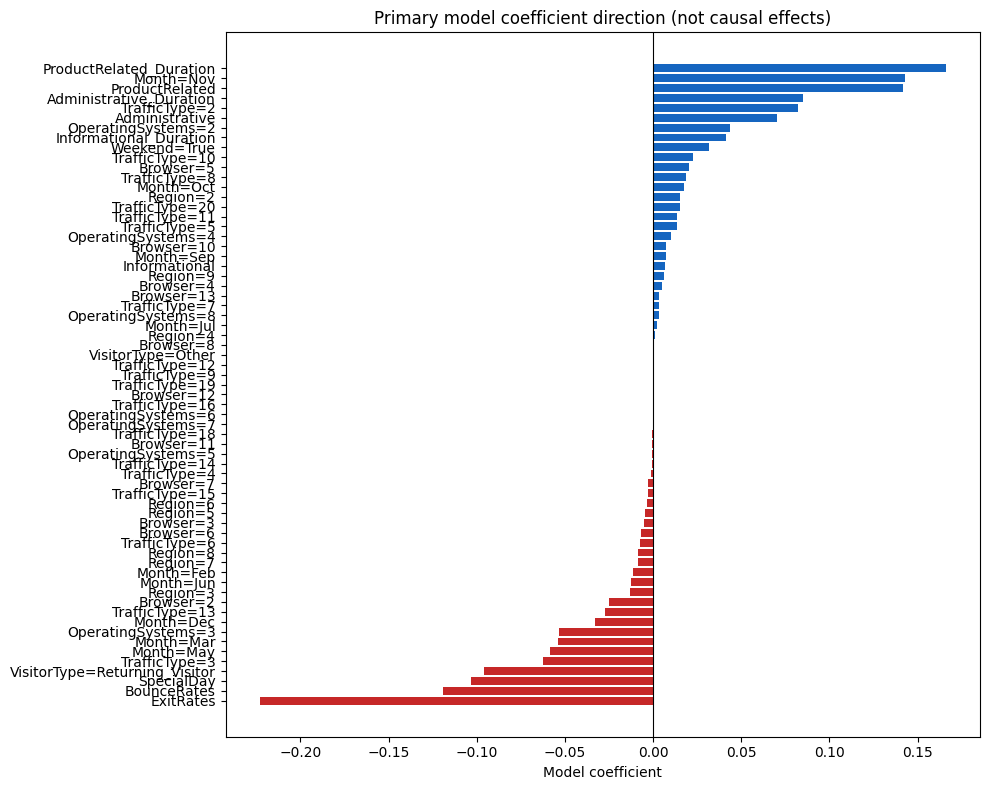

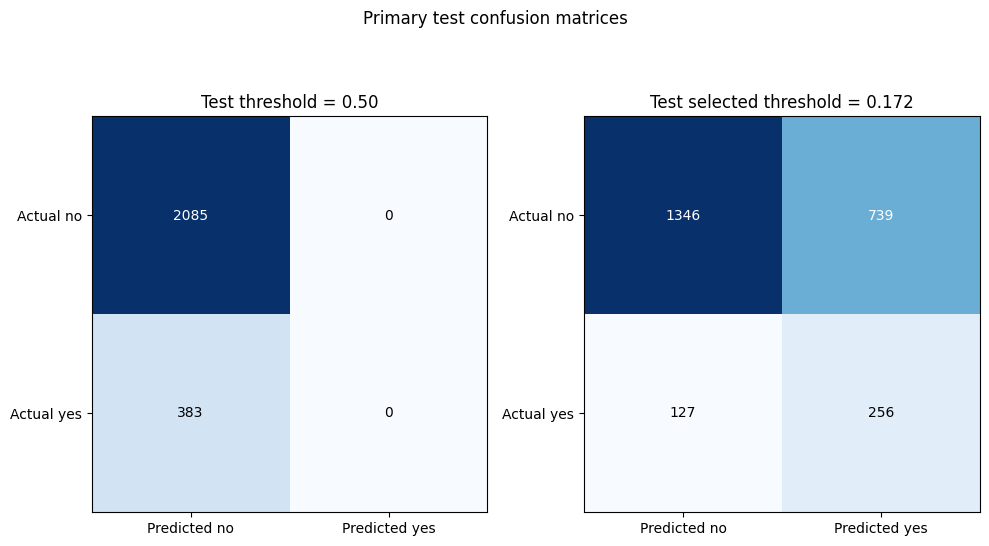

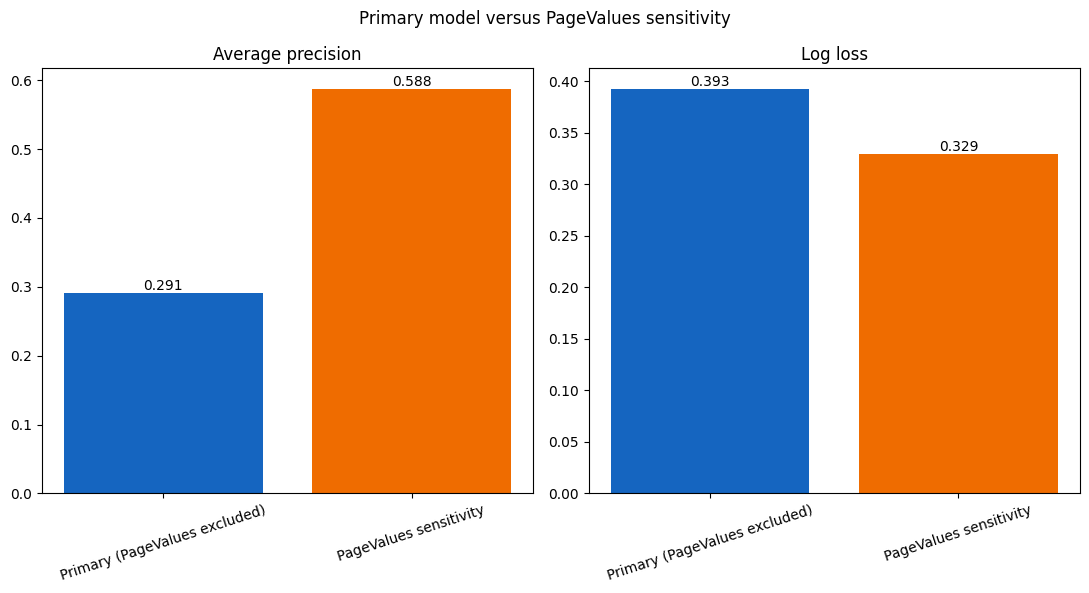

Saved coefficient, confusion-matrix, and sensitivity visuals.


In [2]:
from IPython.display import display
# Additional model visuals
# Coefficient plot is complementary: standardized numeric coefficients and categorical contrasts are not ranked together.
coeff = coefficients.sort_values('coefficient')
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(coeff['feature'], coeff['coefficient'], color=['#c62828' if v < 0 else '#1565c0' for v in coeff['coefficient']])
ax.axvline(0, color='black', linewidth=.8); ax.set_xlabel('Model coefficient'); ax.set_title('Primary model coefficient direction (not causal effects)')
fig.tight_layout(); fig.savefig(figures / '15_primary_model_coefficients.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

# Confusion matrices show the threshold tradeoff more clearly than aggregate scores alone.
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax, threshold_value, title in zip(axes, [.5, selected_threshold], ['Test threshold = 0.50', f'Test selected threshold = {selected_threshold:.3f}']):
    cm = classification_metrics(y_test, primary_test_probability, threshold_value)
    matrix = np.array([[cm['tn'], cm['fp']], [cm['fn'], cm['tp']]])
    image = ax.imshow(matrix, cmap='Blues'); ax.set_xticks([0,1], ['Predicted no', 'Predicted yes']); ax.set_yticks([0,1], ['Actual no', 'Actual yes']); ax.set_title(title)
    for i in range(2):
        for j in range(2): ax.text(j, i, str(matrix[i,j]), ha='center', va='center', color='white' if matrix[i,j] > matrix.max()/2 else 'black')
fig.suptitle('Primary test confusion matrices'); fig.tight_layout(); fig.savefig(figures / '16_primary_confusion_matrices.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)

# Compare the leakage-sensitive model with the primary model without presenting it as deployable.
sensitivity_test = sensitivity_metrics[sensitivity_metrics['split'].eq('test')].iloc[0]
comparison = pd.DataFrame({'model': ['Primary (PageValues excluded)', 'PageValues sensitivity'], 'average_precision': [classification_metrics(y_test, primary_test_probability)['average_precision'], sensitivity_test['average_precision']], 'log_loss': [classification_metrics(y_test, primary_test_probability)['log_loss'], sensitivity_test['log_loss']]})
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
for ax, column, title in zip(axes, ['average_precision', 'log_loss'], ['Average precision', 'Log loss']):
    bars=ax.bar(comparison['model'], comparison[column], color=['#1565c0','#ef6c00']); ax.set_title(title); ax.tick_params(axis='x', rotation=18)
    for bar, value in zip(bars, comparison[column]): ax.text(bar.get_x()+bar.get_width()/2, value, f'{value:.3f}', ha='center', va='bottom')
fig.suptitle('Primary model versus PageValues sensitivity'); fig.tight_layout(); fig.savefig(figures / '17_pagevalues_sensitivity_comparison.png', dpi=220, bbox_inches='tight'); display(fig); plt.close(fig)
print('Saved coefficient, confusion-matrix, and sensitivity visuals.')
